# Inside BLAS

Notebook 04 showed that NumPy's matrix multiplication, which calls a BLAS library, beats our C code by a wide margin. Here we separate the two reasons, better code and more cores, and look at how a BLAS routine is organised.

In [ ]:
import numpy as np
from threadpoolctl import threadpool_info

from compare_efficiency.benchmark import time_function

[{key: library[key] for key in ("internal_api", "version", "num_threads")} for library in threadpool_info()]

[{'internal_api': 'openblas', 'version': '0.3.34.106.0', 'num_threads': 24}]

## Cores and threads

`num_threads` above needs two more ideas:

- A modern CPU contains several **cores**: independent processing units, each able to run its own sequence of instructions. A desktop processor typically has between 6 and 16.
- A **thread** is one sequence of instructions within a program. A program that splits its work into several threads can run them at the same time, on different cores.

Think of a kitchen: one cook (a single thread) prepares dishes one after another; with twelve cooks (twelve threads on twelve cores), twelve dishes can be in progress at once, provided the work can be divided.

`os.cpu_count()` counts *logical* processors, which is often twice the number of physical cores, because each core can interleave two threads.

In [ ]:
import os

os.cpu_count()

24

Our C code from notebook 03 used a single thread. BLAS uses all of them by default. To separate "better code" from "more cooks", we time NumPy twice: limited to one thread with `threadpool_limits`, and with all threads.

In [ ]:
from threadpoolctl import threadpool_limits

from compare_efficiency.benchmark import gflops, random_matrices

numpy_sizes = [256, 512, 1024, 2048, 4096]
matrices_by_size = {n: random_matrices(n) for n in numpy_sizes}

def time_numpy_matmul(n: int) -> float:
    matrix_a, matrix_b = matrices_by_size[n]
    return time_function(lambda: matrix_a @ matrix_b, warmup=3)

with threadpool_limits(limits=1):
    single_thread_seconds = {n: time_numpy_matmul(n) for n in numpy_sizes}
all_threads_seconds = {n: time_numpy_matmul(n) for n in numpy_sizes}
numpy_seconds = {"NumPy, 1 thread": single_thread_seconds, "NumPy, all threads": all_threads_seconds}

{name: {n: f"{gflops(n, seconds):.0f} GFLOPS" for n, seconds in by_size.items()}
 for name, by_size in numpy_seconds.items()}

{'NumPy, 1 thread': {256: '103 GFLOPS',
  512: '112 GFLOPS',
  1024: '123 GFLOPS',
  2048: '127 GFLOPS',
  4096: '132 GFLOPS'},
 'NumPy, all threads': {256: '11 GFLOPS',
  512: '657 GFLOPS',
  1024: '1057 GFLOPS',
  2048: '839 GFLOPS',
  4096: '860 GFLOPS'}}

Look at the smallest size with all threads: it is often *slower* than one thread, and erratic from run to run. A 256 × 256 multiplication lasts a fraction of a millisecond, which is about as long as it takes to wake up and coordinate all those threads (one per logical processor). And when every logical processor is in use, a single one that is busy with something else (the operating system, this notebook) makes the whole operation wait. Threads pay off only when there is enough work to share: from $n = 1024$ upwards, all threads together are several times faster than one.

For comparison, the best C version from notebook 03, measured again now:

In [ ]:
from compare_efficiency.c_library import call_c_matmul, compile_c_library, load_c_library

c_library = load_c_library(compile_c_library(["-O3", "-march=native"], "O3"))
matrix_a, matrix_b = random_matrices(1024)
c_seconds = time_function(lambda: call_c_matmul(c_library.matmul_ikj, matrix_a, matrix_b), repeats=3)
f"C ikj -O3 at n=1024: {gflops(1024, c_seconds):.1f} GFLOPS"

'C ikj -O3 at n=1024: 34.2 GFLOPS'

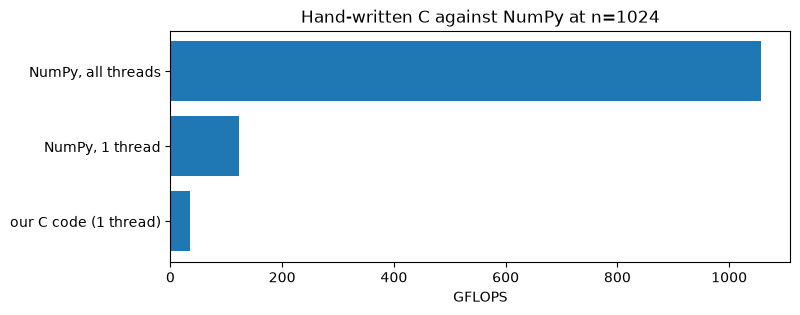

In [ ]:
import matplotlib.pyplot as plt

headline_size = 1024
headline = {
    "our C code (1 thread)": gflops(headline_size, c_seconds),
    "NumPy, 1 thread": gflops(headline_size, numpy_seconds["NumPy, 1 thread"][headline_size]),
    "NumPy, all threads": gflops(headline_size, numpy_seconds["NumPy, all threads"][headline_size]),
}

figure, axis = plt.subplots(figsize=(8, 3))
axis.barh(list(headline), list(headline.values()))
axis.set_xlabel("GFLOPS")
axis.set_title(f"Hand-written C against NumPy at n={headline_size}")
plt.show()

## Why BLAS beats our C code

**One line of Python beats our hand-written C**, even when both use a single thread. BLAS performs the same $2n^3$ operations, but organises them far better:

- **Blocking (tiling).** Imagine a cook who, for every single dish, walks to the pantry for each ingredient. A better cook brings a tray of ingredients to the counter once and uses it for many dishes before going back. BLAS splits the matrices into small blocks that fit in the caches (the deep dive [Numbers and memory](numbers_and_memory.ipynb)), and reuses each block many times while it is close to the processor.
- **Hand-tuned inner code.** The innermost part is written by experts, often directly in machine instructions, separately for each family of processors, to keep every arithmetic unit busy.
- **SIMD and FMA.** It uses the widest **SIMD** instructions available (*Single Instruction, Multiple Data*: one instruction applied to several numbers at once) and **FMA** (*fused multiply-add*) instructions, which compute $a \times b + c$ in a single step: exactly the operation at the heart of a dot product.
- **Multithreading.** With several threads, different blocks of the result are computed on different cores at once.

## The cost of each call

Glue has a cost, but it is a fixed cost **per call**, not per operation. For tiny matrices, that fixed cost is most of the time, and even the pure Python loop can win:

In [ ]:
from compare_efficiency.matmul_pure_python import matmul_pure_python

tiny_a, tiny_b = random_matrices(2)
tiny_list_a, tiny_list_b = tiny_a.tolist(), tiny_b.tolist()
{
    "pure Python, 2x2": f"{time_function(lambda: matmul_pure_python(tiny_list_a, tiny_list_b), repeats=1000) * 1e6:.2f} µs",
    "NumPy, 2x2": f"{time_function(lambda: tiny_a @ tiny_b, repeats=1000) * 1e6:.2f} µs",
}

{'pure Python, 2x2': '0.48 µs', 'NumPy, 2x2': '0.58 µs'}

Both take a fraction of a microsecond, and the pure Python loop may even be faster. For a 1024 × 1024 multiplication, the same fixed cost is lost among milliseconds of real work. So the rule for fast numerical Python is: **few calls, each doing a lot of work**. It is also why AI models process examples in batches (notebook 02).

## How a BLAS routine is organised

Modern BLAS implementations (following the approach published by Kazushige Goto and later used in OpenBLAS and BLIS) organise a matrix multiplication in layers:

1. **Blocking for each cache level**: the loops are split so that one block of $B$ stays in the L3 cache, one block of $A$ in the L2 cache, and a thin sliver of $B$ in the L1 cache.
2. **Packing**: those blocks are copied into small contiguous buffers, in exactly the order the innermost code will read them, so every access is sequential (the deep dive [Numbers and memory](numbers_and_memory.ipynb)).
3. **Micro-kernel**: a tiny routine, written for each CPU family, computes a small block of the result (for example 8 × 12 values) entirely in registers, using SIMD FMA instructions back to back. Everything else exists to keep this micro-kernel supplied with data.

Note what BLAS does *not* do: it still performs the classic $2n^3$ operations. Algorithms with a lower operation count exist (Strassen's, for example), but they are rarely used in practice, because they are less numerically stable and harder to make fast. The whole speed-up comes from using the hardware well.

## Controlling the number of threads

`threadpool_limits` changes the number of BLAS threads only inside a `with` block, as used above. The limit can also be set for a whole program with environment variables such as `OMP_NUM_THREADS` or `OPENBLAS_NUM_THREADS`, which must be set before NumPy is imported. Limiting threads is useful when several programs share a machine, or when a program already runs several processes in parallel: too many threads competing for the same cores slow everything down.

In [ ]:
with threadpool_limits(limits=2):
    limited_threads = [library["num_threads"] for library in threadpool_info()]
limited_threads, [library["num_threads"] for library in threadpool_info()]

([2], [24])

## Key ideas

- A CPU has several **cores**; a program can split its work into **threads** that run on them at the same time.
- BLAS is faster than simple C even on one thread (blocking, SIMD, FMA), and much faster with all threads on large matrices.
- Threads have a fixed cost: for small matrices they can make things slower, and every Python call has a small fixed cost too.
- BLAS still performs the classic $2n^3$ operations; the whole speed-up comes from using the hardware well.